# Questions

How does Fitbit daily steps and total active minutes correlate?

How does daily steps differ between on the weekdays such as Mon - Fri to weekends (Sat - Sun)?

How does NHANES measure the movement by various data such as age and more?

We shorten our questions to activity patterns correlation but still working on it.

In [1]:
import polars as pl
import pandas as pd

fitbit_raw_data = pl.read_csv(
    "data/fitbit/dailyActivity_merged.csv",
    infer_schema_length=None,
)

fitbit_raw_data.head()

Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
i64,str,i64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64
1503960366,"""4/12/2016""",13162,8.5,8.5,0.0,1.88,0.55,6.06,0.0,25,13,328,728,1985
1503960366,"""4/13/2016""",10735,6.97,6.97,0.0,1.57,0.69,4.71,0.0,21,19,217,776,1797
1503960366,"""4/14/2016""",10460,6.74,6.74,0.0,2.44,0.4,3.91,0.0,30,11,181,1218,1776
1503960366,"""4/15/2016""",9762,6.28,6.28,0.0,2.14,1.26,2.83,0.0,29,34,209,726,1745
1503960366,"""4/16/2016""",12669,8.16,8.16,0.0,2.71,0.41,5.04,0.0,36,10,221,773,1863


In [2]:
fitbit_raw_data.shape

(940, 15)

In [3]:
fitbit_raw_data.schema

Schema([('Id', Int64),
        ('ActivityDate', String),
        ('TotalSteps', Int64),
        ('TotalDistance', Float64),
        ('TrackerDistance', Float64),
        ('LoggedActivitiesDistance', Float64),
        ('VeryActiveDistance', Float64),
        ('ModeratelyActiveDistance', Float64),
        ('LightActiveDistance', Float64),
        ('SedentaryActiveDistance', Float64),
        ('VeryActiveMinutes', Int64),
        ('FairlyActiveMinutes', Int64),
        ('LightlyActiveMinutes', Int64),
        ('SedentaryMinutes', Int64),
        ('Calories', Int64)])

In [4]:
fitbit_raw_data.null_count()

Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [5]:
fitbit_raw_data.describe()

statistic,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",940.0,"""940""",940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0,940.0
"""null_count""",0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",4.8554e9,null,7637.910638,5.489702,5.475351,0.108171,1.502681,0.567543,3.340819,0.001606,21.164894,13.564894,192.812766,991.210638,2303.609574
"""std""",2.4248e9,null,5087.150742,3.924606,3.907276,0.619897,2.658941,0.88358,2.040655,0.007346,32.844803,19.987404,109.1747,301.267437,718.166862
"""min""",1.5040e9,"""4/12/2016""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",2.3201e9,null,3790.0,2.62,2.62,0.0,0.0,0.0,1.95,0.0,0.0,0.0,127.0,730.0,1829.0
"""50%""",4.4451e9,null,7412.0,5.25,5.25,0.0,0.21,0.24,3.37,0.0,4.0,6.0,199.0,1058.0,2135.0
"""75%""",6.9622e9,null,10725.0,7.71,7.71,0.0,2.04,0.8,4.78,0.0,32.0,19.0,264.0,1229.0,2793.0
"""max""",8.8777e9,"""5/9/2016""",36019.0,28.030001,28.030001,4.942142,21.92,6.48,10.71,0.11,210.0,143.0,518.0,1440.0,4900.0


# Fitbit datasets profiles

# 940 rows & 15 cols. each row represents one person activity per day (one)

# AcivityDate is convert from text to date (weekdays + weekends). Other random variables are ints such as steps and activity minutes. Additional distance is in decimial value

# The minimiuim steps are 0 and also for calories without no null values shown.

# avg step is 7,638 with a deviation of 5,087 acrross days.

In [6]:
zero_days = fitbit_raw_data.filter(pl.col("TotalSteps") == 0)

zero_days.shape

(77, 15)

In [7]:
zero_c_days = fitbit_raw_data.filter(pl.col("Calories") == 0)

zero_c_days.shape

(4, 15)

In [8]:
zero_c_days.select(
    "Id",
    "ActivityDate",
    "TotalSteps",
    "VeryActiveMinutes",
    "LightlyActiveMinutes",
    "SedentaryMinutes",
    "Calories",
)

Id,ActivityDate,TotalSteps,VeryActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
i64,str,i64,i64,i64,i64,i64
1503960366,"""5/12/2016""",0,0,0,1440,0
6290855005,"""5/10/2016""",0,0,0,1440,0
8253242879,"""4/30/2016""",0,0,0,1440,0
8583815059,"""5/12/2016""",0,0,0,1440,0


# zero value anomalies

# 77 zero step days and 4 with zero calories, and with 1440 sedentary minutes

# We should exclude the raw values because may indicate not complete accurate data such as activity to inacivity to acitivity.



In [9]:
d_cond = fitbit_raw_data.is_duplicated()

d_rows = fitbit_raw_data.filter(d_cond)

d_rows.shape

(0, 15)

# Also no duplicates rows.

In [10]:
negative_condition = (pl.col("TotalSteps") < 0) | (pl.col("VeryActiveMinutes") < 0) | (pl.col("FairlyActiveMinutes") < 0) | (pl.col("LightlyActiveMinutes") < 0) | (pl.col("SedentaryMinutes") < 0) | (pl.col("Calories") < 0)

negative_rows = fitbit_raw_data.filter(negative_condition)

negative_rows.shape

(0, 15)

In [11]:
fitbit_data = fitbit_raw_data.with_columns(pl.col("ActivityDate").str.strptime(pl.Date, format="%m/%d/%Y"))

fitbit_data.schema

Schema([('Id', Int64),
        ('ActivityDate', Date),
        ('TotalSteps', Int64),
        ('TotalDistance', Float64),
        ('TrackerDistance', Float64),
        ('LoggedActivitiesDistance', Float64),
        ('VeryActiveDistance', Float64),
        ('ModeratelyActiveDistance', Float64),
        ('LightActiveDistance', Float64),
        ('SedentaryActiveDistance', Float64),
        ('VeryActiveMinutes', Int64),
        ('FairlyActiveMinutes', Int64),
        ('LightlyActiveMinutes', Int64),
        ('SedentaryMinutes', Int64),
        ('Calories', Int64)])

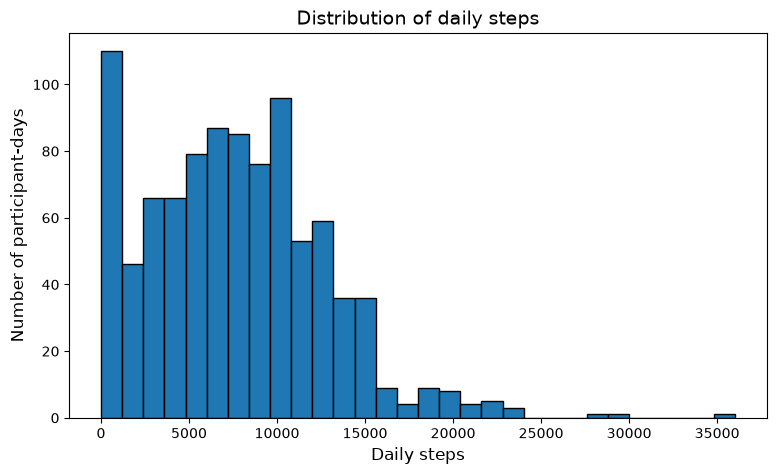

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["TotalSteps"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Daily steps", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of daily steps", fontsize=14)
plt.show()

# Daily steps distribution

# right skewed data on 15k steps and a tail on 36k steps. Mean is around 7638 and median to be 7412. middle 50% fall between around 3790 to 10725. Additional details are 77 zero step days as other very low days.

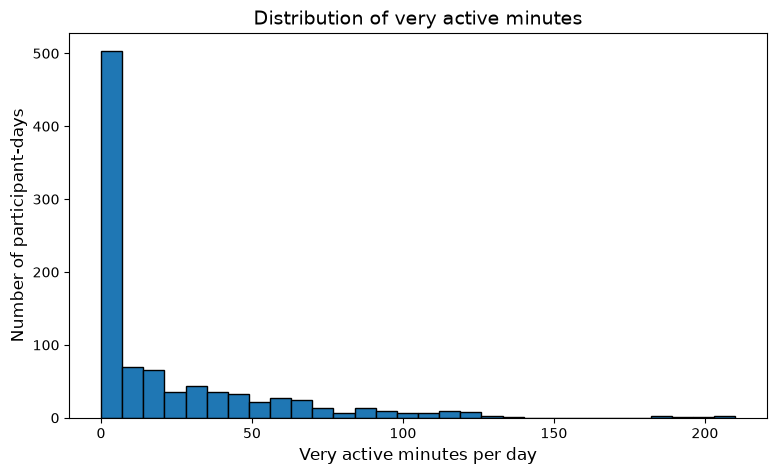

In [13]:
plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["VeryActiveMinutes"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Very active minutes per day", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of very active minutes", fontsize=14)
plt.show()

# Very active minutes distri

# right skewed toward trend data with and upper tail. While the bin includes the both zero value and small one too. Median is 4 minutes, with the means at 21.16 and middle 50% between 0 to 32 mins, with range being 0 to 210. The means is above the median too

In [14]:
fitbit_data.select("VeryActiveMinutes").describe()


statistic,VeryActiveMinutes
str,f64
"""count""",940.0
"""null_count""",0.0
"""mean""",21.164894
"""std""",32.844803
"""min""",0.0
"""25%""",0.0
"""50%""",4.0
"""75%""",32.0
"""max""",210.0


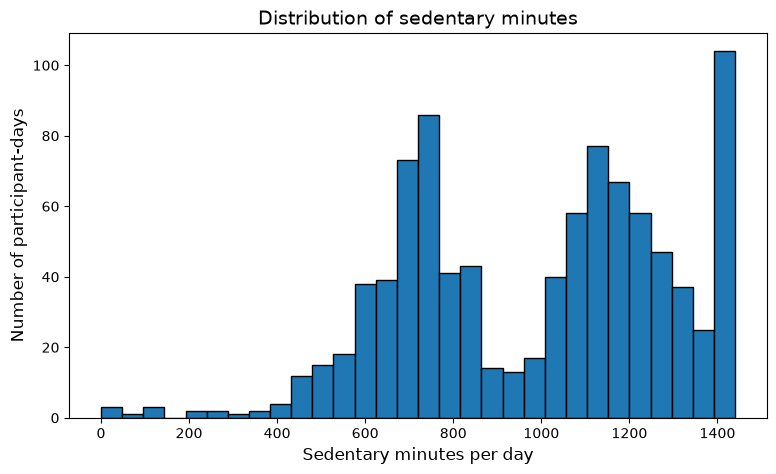

In [15]:
plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["SedentaryMinutes"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Sedentary minutes per day", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of sedentary minutes", fontsize=14)
plt.show()

In [16]:
fitbit_data.select("SedentaryMinutes").describe()

statistic,SedentaryMinutes
str,f64
"""count""",940.0
"""null_count""",0.0
"""mean""",991.210638
"""std""",301.267437
"""min""",0.0
"""25%""",730.0
"""50%""",1058.0
"""75%""",1229.0
"""max""",1440.0


# Sedentary min distri

# Mean is 991 mins, median is 1058, and middle 50% is between 730 to 1229, with a big range of 0 to 1440minss

# the tail toward the low vals.

In [17]:
full_day_condition = pl.col("SedentaryMinutes") == 1440

full_day_rows = fitbit_data.filter(full_day_condition)

full_day_rows.shape

(79, 15)

In [18]:
full_day_rows.select("Id", "ActivityDate", "TotalSteps", "Calories")

Id,ActivityDate,TotalSteps,Calories
i64,date,i64,i64
1503960366,2016-05-12,0,0
1844505072,2016-04-24,0,1347
1844505072,2016-04-25,0,1347
1844505072,2016-04-26,0,1347
1844505072,2016-05-02,0,1348
…,…,…,…
8792009665,2016-05-05,0,1688
8792009665,2016-05-06,0,1688
8792009665,2016-05-07,0,1688


# 79 days with record of 1440 sedentary mins. 72 with no steps and 7 pos steps. 

This also suggest inconsistent between our data on the sendtary time compared to the movement of xyz.

In [19]:
full_day_zero_steps = full_day_rows.filter(pl.col("TotalSteps") == 0)

full_day_zero_steps.shape

(72, 15)

In [20]:
full_day_positive_steps = full_day_rows.filter(pl.col("TotalSteps") > 0)

full_day_positive_steps.select("Id", "ActivityDate", "TotalSteps", "Calories")

Id,ActivityDate,TotalSteps,Calories
i64,date,i64,i64
4319703577,2016-04-12,7753,2115
4388161847,2016-04-12,10122,2955
8583815059,2016-04-16,5319,2693
8583815059,2016-04-17,3008,2439
8583815059,2016-05-02,8469,2894
8583815059,2016-05-03,12015,3212
8583815059,2016-05-04,3588,2516


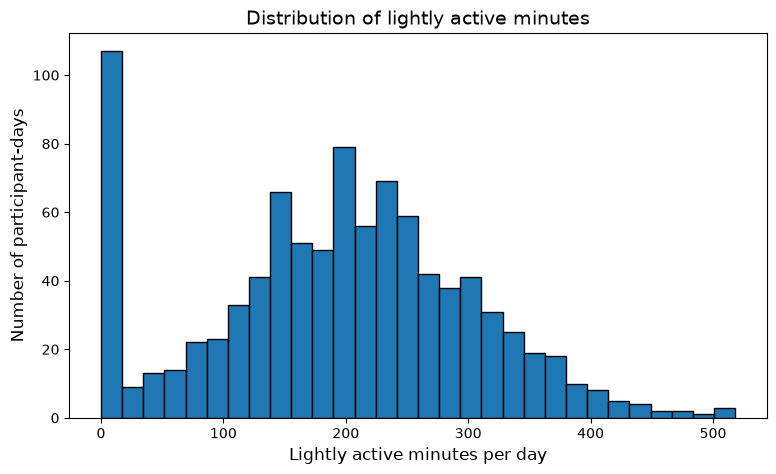

In [21]:
plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["LightlyActiveMinutes"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Lightly active minutes per day", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of lightly active minutes", fontsize=14)
plt.show()

In [22]:
fitbit_data.select("LightlyActiveMinutes").describe()

statistic,LightlyActiveMinutes
str,f64
"""count""",940.0
"""null_count""",0.0
"""mean""",192.812766
"""std""",109.1747
"""min""",0.0
"""25%""",127.0
"""50%""",199.0
"""75%""",264.0
"""max""",518.0


# lightly active minutes distri

# About 200 minutes with mean at 192.81 minute and median is about 199. The middle 50% falls between 127 and 264 minutes, with vals at 0 to 518.

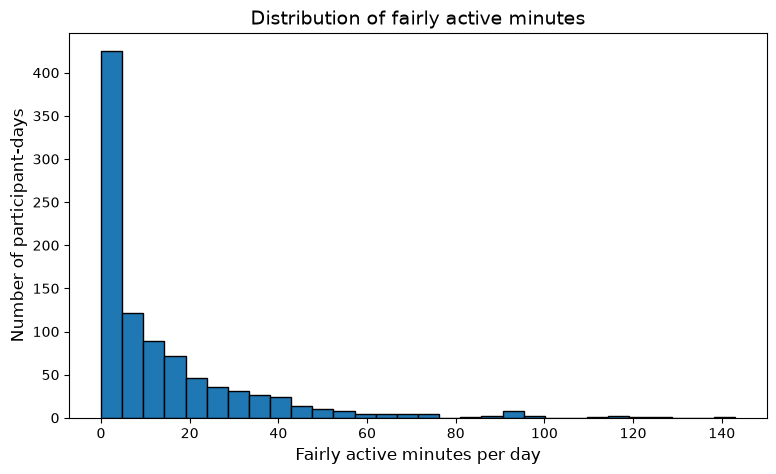

In [23]:
plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["FairlyActiveMinutes"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Fairly active minutes per day", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of fairly active minutes", fontsize=14)
plt.show()

In [24]:
fitbit_data.select("FairlyActiveMinutes").describe()

statistic,FairlyActiveMinutes
str,f64
"""count""",940.0
"""null_count""",0.0
"""mean""",13.564894
"""std""",19.987404
"""min""",0.0
"""25%""",0.0
"""50%""",6.0
"""75%""",19.0
"""max""",143.0


# Fairly active mins distri

# Right skewed with particpiant days with some near zero and even a long tail at the upper. The mean is at 13.56 and median is 6 minutes. The middle 50% falls between 0 and 19 and range of 0 to 143.

In [25]:
active_minutes = pl.col("LightlyActiveMinutes") + pl.col("FairlyActiveMinutes") + pl.col("VeryActiveMinutes")

fitbit_data = fitbit_data.with_columns(active_minutes.alias("ActiveMinutes"))

fitbit_data.select("LightlyActiveMinutes", "FairlyActiveMinutes", "VeryActiveMinutes", "ActiveMinutes").head()

LightlyActiveMinutes,FairlyActiveMinutes,VeryActiveMinutes,ActiveMinutes
i64,i64,i64,i64
328,13,25,366
217,19,21,257
181,11,30,222
209,34,29,272
221,10,36,267


# Active Minutes is is inclusion of all sum of data on participant days.

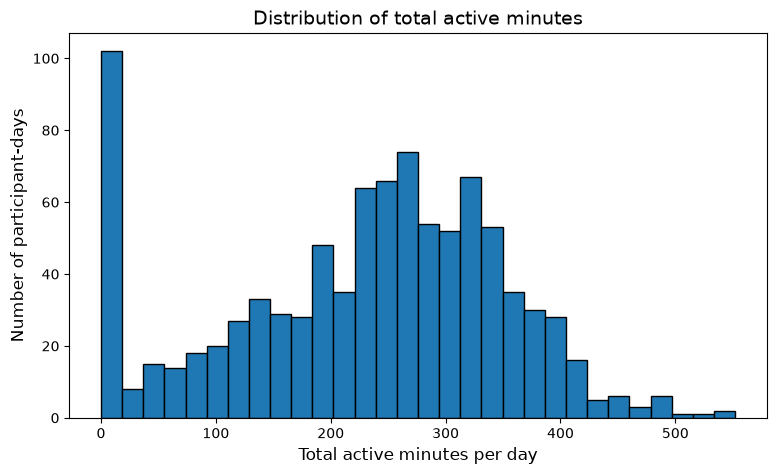

In [26]:
plt.figure(figsize=(9, 5))
plt.hist(fitbit_data["ActiveMinutes"].to_numpy(), bins=30, edgecolor="black")
plt.xlabel("Total active minutes per day", fontsize=12)
plt.ylabel("Number of participant-days", fontsize=12)
plt.title("Distribution of total active minutes", fontsize=14)
plt.show()

In [27]:
fitbit_data.select("ActiveMinutes").describe()

statistic,ActiveMinutes
str,f64
"""count""",940.0
"""null_count""",0.0
"""mean""",227.542553
"""std""",121.776307
"""min""",0.0
"""25%""",147.0
"""50%""",247.0
"""75%""",317.0
"""max""",552.0


# Total active minutes distribution

Active Minutes is the sum of equation for all type of energy from light to very hyper active for each xyz day.

The mean is 227.54 minutes and the median is 247 mins. The middle 50% falls between the 147 to 317 and a range from 0 to 552. Relating in some spike in near to bottom 0 with some higher spikes.

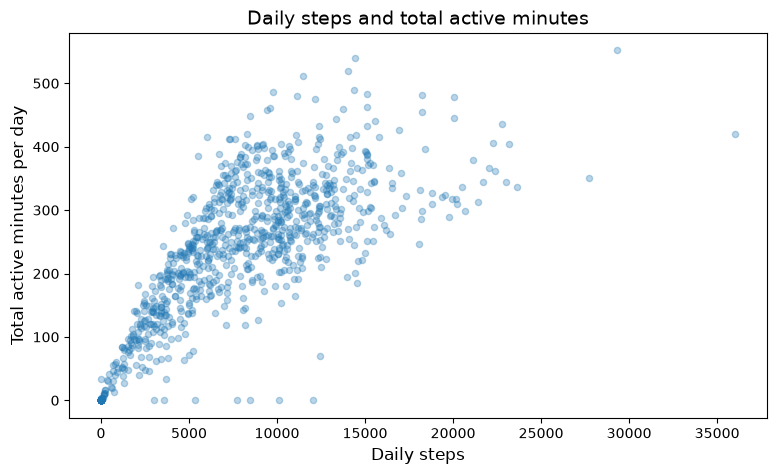

In [28]:
plt.figure(figsize=(9, 5))
plt.scatter(fitbit_data["TotalSteps"].to_numpy(), fitbit_data["ActiveMinutes"].to_numpy(), alpha=0.3, s=20)
plt.xlabel("Daily steps", fontsize=12)
plt.ylabel("Total active minutes per day", fontsize=12)
plt.title("Daily steps and total active minutes", fontsize=14)
plt.show()

# Relationship between daily steps and active minutes (total)

Higher steps always correlate with higher minute count because more will always result in more but active minutes may vary substantially at similar step count depending on speed etc. 

This relates us to deep dive into the research of postive days of steps with lower to none minutes to look for outliers data that may not correlate with our databsets.



In [29]:
weekday_number = pl.col("ActivityDate").dt.weekday()

day_type = pl.when(weekday_number >= 6).then(pl.lit("Weekend")).otherwise(pl.lit("Weekday"))

fitbit_data = fitbit_data.with_columns(day_type.alias("DayType"))

fitbit_data.select("ActivityDate", "DayType").head(7)

ActivityDate,DayType
date,str
2016-04-12,"""Weekday"""
2016-04-13,"""Weekday"""
2016-04-14,"""Weekday"""
2016-04-15,"""Weekday"""
2016-04-16,"""Weekend"""
2016-04-17,"""Weekend"""
2016-04-18,"""Weekday"""


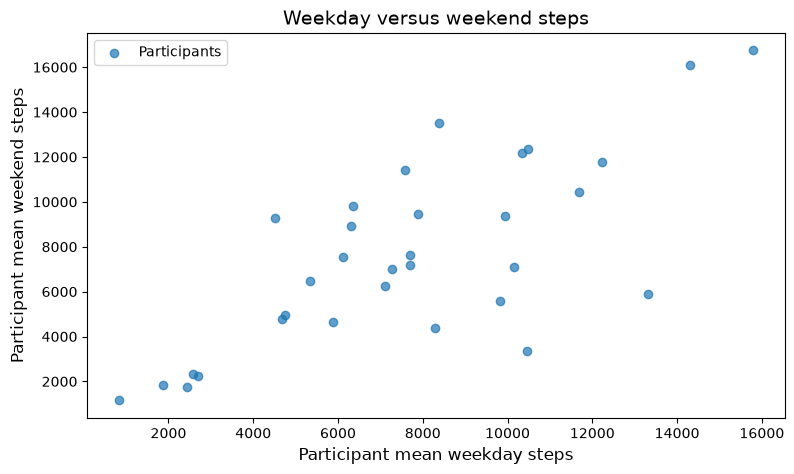

statistic,Weekday,Weekend,WeekendDifference
str,f64,f64,f64
"""count""",32.0,32.0,32.0
"""null_count""",0.0,0.0,0.0
"""mean""",7650.151882,7606.677865,-43.474018
"""std""",3678.444883,4092.856354,2860.537255
"""min""",832.652174,1156.125,-7435.406015
"""25%""",5332.952381,4797.75,-698.478261
"""50%""",7690.043478,7169.75,-25.511905
"""75%""",10161.0,9807.0,1567.761364
"""max""",15792.608696,16751.375,5145.857143


Participants compared: 32
Higher weekend steps: 15


In [30]:
participant_steps = fitbit_data.group_by("Id", "DayType").agg(pl.col("TotalSteps").mean().alias("MeanSteps"))

paired_steps = participant_steps.pivot(on="DayType", index="Id", values="MeanSteps").drop_nulls(["Weekday", "Weekend"])

plt.figure(figsize=(9, 5))
plt.scatter(paired_steps["Weekday"].to_numpy(),paired_steps["Weekend"].to_numpy(),alpha=0.7, label="Participants")

limit = max(paired_steps["Weekday"].max(), paired_steps["Weekend"].max())
plt.xlabel("Participant mean weekday steps", fontsize=12)
plt.ylabel("Participant mean weekend steps", fontsize=12)
plt.title("Weekday versus weekend steps", fontsize=14)
plt.legend()
plt.show()

paired_steps = paired_steps.with_columns(
    (pl.col("Weekend") - pl.col("Weekday")).alias("WeekendDifference")
)

display(paired_steps.select("Weekday", "Weekend", "WeekendDifference").describe())
print("Participants compared:", paired_steps.height)
print("Higher weekend steps:", paired_steps.filter(pl.col("WeekendDifference") > 0).height)

# Relationship 2

In the 32 particpants, 15 were taller than the avg weekend steps. More correlation with higher steps on weekends while other particpants walked more the weekdays (mon - fri.). 7650 on the weekdyas to 7607 on the weekends.

We could look closer into the data on saturday and sunday but there show no major correlation with weekdays and weekend being similar data.

## NHANES Physical Activity Monitor - Exploratory Data Analysis
This section explores the NHANES 2011-2012 Physical Activity Monitor - Day dataset (PAXDAY_G)

In [31]:
nhanes_raw_data = pd.read_sas("data/cdc/PAXDAY_G.xpt", format="xport")

nhanes_data = pl.from_pandas(nhanes_raw_data)

nhanes_data.head()

SEQN,PAXDAYD,PAXDAYWD,PAXSSNDP,PAXMSTD,PAXTMD,PAXAISMD,PAXVMD,PAXMTSD,PAXWWMD,PAXSWMD,PAXNWMD,PAXUMD,PAXLXSD,PAXQFD
f64,binary,binary,f64,binary,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
62161.0,"b""1""","b""7""",5.3976e-79,"b""12:30:00""",690.0,1.426946e6,690.0,4636.399,508.0,139.0,5.3976e-79,43.0,49185.11,5.3976e-79
62161.0,"b""2""","b""1""",3.312e6,"b""\x200:00:00""",1440.0,3.123802e6,1440.0,12531.363,816.0,548.0,5.3976e-79,76.0,433309.24,5.3976e-79
62161.0,"b""3""","b""2""",1.0224e7,"b""\x200:00:00""",1440.0,2.779464e6,1440.0,14013.228,921.0,462.0,5.3976e-79,57.0,475977.11,5.3976e-79
62161.0,"b""4""","b""3""",1.7136e7,"b""\x200:00:00""",1440.0,2.724602e6,1440.0,16982.386,911.0,472.0,5.3976e-79,57.0,208827.73,5.3976e-79
62161.0,"b""5""","b""4""",2.4048e7,"b""\x200:00:00""",1440.0,3.144826e6,1440.0,11718.5,854.0,504.0,5.3976e-79,82.0,114269.65,5.3976e-79


### NHANES Dataset Profile
We examine the structure of the NHANES Physical Activity Monitor dataset

In [32]:
# Dataset dimensions
print("Dataset shape:", nhanes_data.shape)

Dataset shape: (61168, 15)


In [33]:
# Columns names and data types
print("\nColumns information:")
nhanes_data.glimpse()


Columns information:
Rows: 61168
Columns: 15
$ SEQN        <f64> 62161.0, 62161.0, 62161.0, 62161.0, 62161.0, 62161.0, 62161.0, 62161.0, 62161.0, 62163.0
$ PAXDAYD  <binary> b'1', b'2', b'3', b'4', b'5', b'6', b'7', b'8', b'9', b'1'
$ PAXDAYWD <binary> b'7', b'1', b'2', b'3', b'4', b'5', b'6', b'7', b'1', b'7'
$ PAXSSNDP    <f64> 5.397605346934028e-79, 3312000.0, 10224000.0, 17136000.0, 24048000.0, 30960000.0, 37872000.0, 44784000.0, 51696000.0, 5.397605346934028e-79
$ PAXMSTD  <binary> b'12:30:00', b' 0:00:00', b' 0:00:00', b' 0:00:00', b' 0:00:00', b' 0:00:00', b' 0:00:00', b' 0:00:00', b' 0:00:00', b'17:30:00'
$ PAXTMD      <f64> 690.0, 1440.0, 1440.0, 1440.0, 1440.0, 1440.0, 1440.0, 1440.0, 760.0, 390.0
$ PAXAISMD    <f64> 1426946.0, 3123802.0, 2779464.0, 2724602.0, 3144826.0, 3001421.0, 4079193.0, 2798564.0, 3463791.0, 33043.0
$ PAXVMD      <f64> 690.0, 1440.0, 1440.0, 1440.0, 1440.0, 1440.0, 1440.0, 1440.0, 760.0, 390.0
$ PAXMTSD     <f64> 4636.399, 12531.363, 14013.228, 16982.3

In [34]:
# Missing values
print("\nMissing values:")
display(nhanes_data.null_count())


Missing values:


SEQN,PAXDAYD,PAXDAYWD,PAXSSNDP,PAXMSTD,PAXTMD,PAXAISMD,PAXVMD,PAXMTSD,PAXWWMD,PAXSWMD,PAXNWMD,PAXUMD,PAXLXSD,PAXQFD
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [35]:
# Descriptive statistics
print("\nDescriptive statistics:")
display(nhanes_data.describe())


Descriptive statistics:


statistic,SEQN,PAXDAYD,PAXDAYWD,PAXSSNDP,PAXMSTD,PAXTMD,PAXAISMD,PAXVMD,PAXMTSD,PAXWWMD,PAXSWMD,PAXNWMD,PAXUMD,PAXLXSD,PAXQFD
str,f64,str,str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",61168.0,"""61168""","""61168""",61168.0,"""61168""",61168.0,61168.0,61168.0,61168.0,61168.0,61168.0,61168.0,61168.0,61168.0,61168.0
"""null_count""",0.0,"""0""","""0""",0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",67020.577393,null,null,2.3393e7,null,1277.250458,2.8498e6,1275.465897,11367.280024,703.114177,383.338903,144.729287,44.283531,126644.534814,2.06062
"""std""",2810.2315,null,null,1.7106e7,null,333.717026,1.2883e6,334.558732,6843.649392,340.368957,213.182394,328.499549,26.949677,165312.699793,39.183591
"""min""",62161.0,"""b'1'""","""b'1'""",5.3976e-79,"""b' 0:00:00'""",4.0,5.3976e-79,5.3976e-79,5.3976e-79,5.3976e-79,5.3976e-79,5.3976e-79,5.3976e-79,5.3976e-79,5.3976e-79
"""25%""",64596.0,null,null,8.784e6,null,1440.0,2.271919e6,1434.0,6261.431,487.0,277.0,5.3976e-79,26.0,14732.24,5.3976e-79
"""50%""",67024.0,null,null,2.2608e7,null,1440.0,2.7718e6,1440.0,11678.904,846.0,418.0,5.3976e-79,42.0,69535.92,5.3976e-79
"""75%""",69437.0,null,null,3.7872e7,null,1440.0,3.373349e6,1440.0,16100.176,953.0,510.0,10.0,60.0,174031.86,5.3976e-79
"""max""",71916.0,"""b'9'""","""b'7'""",5.27184e7,"""b'21:30:00'""",1440.0,6.912e6,1440.0,50683.232,1437.0,1440.0,1440.0,288.0,1.9676e6,2880.0


### NHANES Data Cleaning and Anomaly Detection
The NHANES dataset contains variables imported as binary values from the SAS file. First, we must convert columns to readable strings, then investigate unusual values and missing observations

In [36]:
nhanes_data = nhanes_data.with_columns(
    pl.col("PAXDAYD").map_elements(
        lambda x: x.decode("utf-8"),
        return_dtype=pl.String
    ),
    pl.col("PAXDAYWD").map_elements(
        lambda x: x.decode("utf-8"),
        return_dtype=pl.String
    ),
    pl.col("PAXMSTD").map_elements(
        lambda x: x.decode("utf-8"),
        return_dtype=pl.String
    )
)

# Verify the conversions
nhanes_data.select("PAXDAYD", "PAXDAYWD", "PAXMSTD").head()

PAXDAYD,PAXDAYWD,PAXMSTD
str,str,str
"""1""","""7""","""12:30:00"""
"""2""","""1""",""" 0:00:00"""
"""3""","""2""",""" 0:00:00"""
"""4""","""3""",""" 0:00:00"""
"""5""","""4""",""" 0:00:00"""


### Investigating Potential Missing Values
Although the dataset initially reported zero null values, there are values that are extremely close to zero, so we must investigate these values

In [37]:
# Identify numeric columns, excluding participant IDs
numeric_columns = [
    col for col, dtype in nhanes_data.schema.items()
    if dtype in (pl.Float64, pl.Float32)
    and col != "SEQN"
]

# Count extremely small positive values in each column
small_value_count = nhanes_data.select(
    [
        ((pl.col(col) > 0) & (pl.col(col) < 1e-70))
        .sum()
        .alias(col)
        for col in numeric_columns
    ]
)

display(small_value_count)

PAXSSNDP,PAXTMD,PAXAISMD,PAXVMD,PAXMTSD,PAXWWMD,PAXSWMD,PAXNWMD,PAXUMD,PAXLXSD,PAXQFD
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
6917,0,58,6,172,2031,4483,45729,1759,1837,53618


### Examining Suspicious Numeric Values
Several numeric columns contain extremely small positive values. We must compare them to see if they share a common representation that allows us to conclude it as an artifact of SAS import process.

In [38]:
# Examine unique suspicious values in selected columns
for col in ["PAXNWMD", "PAXQFD", "PAXSSNDP"]:
    suspicious_values = (
        nhanes_data
        .filter(
            (pl.col(col) > 0) &
            (pl.col(col) < 1e-70)
        )
        .select(col)
        .unique()
        .sort(col)
    )

    print(f"\nColumn: {col}")
    print("Number of unique suspicious values:", suspicious_values.height)
    display(suspicious_values.head(10))


Column: PAXNWMD
Number of unique suspicious values: 1


PAXNWMD
f64
5.3976e-79



Column: PAXQFD
Number of unique suspicious values: 1


PAXQFD
f64
5.3976e-79



Column: PAXSSNDP
Number of unique suspicious values: 1


PAXSSNDP
f64
5.3976e-79


### Verifying Suspicious Values in the Original Data
The same extremely small numeric value appears repeatedly across multiple NHANES columns. We must check the original data to see if they existed originally or if they occurred after the Polars conversion.

In [39]:
# Check suspicious values in the original panda DataFrame
for col in ["PAXNWMD", "PAXQFD", "PAXSSNDP"]:
    suspicious = nhanes_raw_data.loc[
        (nhanes_raw_data[col] > 0) &
        (nhanes_raw_data[col] < 1e-70),
        col
        ]

    print(f"\nColumn: {col}")
    print("Suspicious values:", len(suspicious))
    print("Unique values:", suspicious.unique())
    print("Actual missing values:", nhanes_raw_data[col].isna().sum())
    


Column: PAXNWMD
Suspicious values: 45729
Unique values: [5.39760535e-79]
Actual missing values: 0

Column: PAXQFD
Suspicious values: 53618
Unique values: [5.39760535e-79]
Actual missing values: 0

Column: PAXSSNDP
Suspicious values: 6917
Unique values: [5.39760535e-79]
Actual missing values: 0


### Investigate SAS Missing_Value Representation
The suspicious numeric values were present immediately after importing the SAS file into pandas. We must investigate if these values represent missing observations

In [40]:
for col in ["PAXNWMD", "PAXQFD", "PAXSSNDP"]:
    print(f"\nColumn: {col}")

    print(nhanes_raw_data[col].value_counts(dropna=False).head(10))


Column: PAXNWMD
PAXNWMD
5.397605e-79    45729
1.440000e+03      983
7.590000e+02      181
7.600000e+02      166
1.439000e+03      138
1.059000e+03       92
1.436000e+03       56
1.060000e+03       55
1.438000e+03       44
7.580000e+02       42
Name: count, dtype: int64

Column: PAXQFD
PAXQFD
5.397605e-79    53618
3.000000e+00     5059
6.000000e+00      955
9.000000e+00      348
1.200000e+01      133
4.000000e+00      133
7.000000e+00       87
1.500000e+01       64
5.000000e+00       55
1.000000e+01       51
Name: count, dtype: int64

Column: PAXSSNDP
PAXSSNDP
5.397605e-79    6917
3.312000e+06    3344
1.022400e+07    3333
1.713600e+07    3324
2.404800e+07    3307
3.096000e+07    3279
3.787200e+07    3259
4.478400e+07    3233
5.169600e+07    3204
1.872000e+06    2187
Name: count, dtype: int64


### Counting Rows with Suspicious Values
Several NHANES numeric columns contain extremely small positive values. We must count how many unique rows contain at least one of these values to understand how much data is affected by these suspicious values

In [41]:
# Identify rows containing at least one suspicious numeric value
suspicious_condition = pl.any_horizontal(
    [
        (pl.col(col) > 0) & (pl.col(col) < 1e-70)
        for col in numeric_columns
    ]
)

# Count affected rows
affected_rows = nhanes_data.filter(suspicious_condition).height

print("Total rows:", nhanes_data.height)
print("Rows with suspicious values:", affected_rows)
print("Rows without suspicious values:", nhanes_data.height - affected_rows)

print(
    "Percentage affected:",
    round(affected_rows / nhanes_data.height * 100, 2),
    "%"
)

Total rows: 61168
Rows with suspicious values: 60267
Rows without suspicious values: 901
Percentage affected: 98.53 %


In [42]:
# Check suspicious values against zero
for col in ["PAXNWMD", "PAXQFD", "PAXSSNDP"]:
    print(f"\nColumn: {col}")

    print("Exact zeros:", (nhanes_raw_data[col] == 0).sum())

    print(
        "Suspicious values:",
        ((nhanes_raw_data[col] > 0) &
         (nhanes_raw_data[col] < 1e-70)).sum()
    )

    print("Minimum value:", nhanes_raw_data[col].min())


Column: PAXNWMD
Exact zeros: 0
Suspicious values: 45729
Minimum value: 5.397605346934028e-79

Column: PAXQFD
Exact zeros: 0
Suspicious values: 53618
Minimum value: 5.397605346934028e-79

Column: PAXSSNDP
Exact zeros: 0
Suspicious values: 6917
Minimum value: 5.397605346934028e-79


### Conclusion regarding Suspicious Values
The NHANES dataset contains extremely small positive values across several numeric columns. These values are likely artifacts associated with reading the SAS data, since they are extremely close to zero and appear in variables where zero is a valid value.

For this analysis, we will be treating those suspicious values as zeros. We created a cleaned copy of the dataset and replaced the positive values smaller than 1e-70 with 0.0.

The cleaning process affected 60,267 of the 61,168 records.

After cleaning, no suspicious near-zero values remained, and the dataset retained its original dimensions of 61,168 rows and 15 columns.

This way, we can assume those extremely small values represent zeros rather than a meaningful value that will affect our data.

In [43]:
# Create a cleaned copy of the NHANES dataset
nhanes_clean = nhanes_data.clone()

# Replace suspicious near-zero values with actual zeros
nhanes_clean = nhanes_clean.with_columns(
    [
        pl.when(
            (pl.col(col) > 0) &
            (pl.col(col) < 1e-70)
        )
        .then(0.0)
        .otherwise(pl.col(col))
        .alias(col)
        for col in numeric_columns
    ]
)

# Verify cleaning
print("Original dataset shape:", nhanes_data.shape)
print("Cleaned dataset shape:", nhanes_clean.shape)

print("\nRemaining suspicious values:")

display(
    nhanes_clean.select(
        [
            (
                (pl.col(col) > 0) &
                (pl.col(col) < 1e-70)
            )
            .sum()
            .alias(col)
            for col in numeric_columns
        ]
    )
)

Original dataset shape: (61168, 15)
Cleaned dataset shape: (61168, 15)

Remaining suspicious values:


PAXSSNDP,PAXTMD,PAXAISMD,PAXVMD,PAXMTSD,PAXWWMD,PAXSWMD,PAXNWMD,PAXUMD,PAXLXSD,PAXQFD
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0


## NHANES Distribution Analysis
We will now examine the distributions of key physical activity measurements to identify patterns and/or limitations in the dataset

### Distribution of Daily Valid Monitor Minutes
The variable PAXVMD represents the number of valid monitor minutes recorded during a day. We can examine the distribution to understand how complete the daily monitoring records are

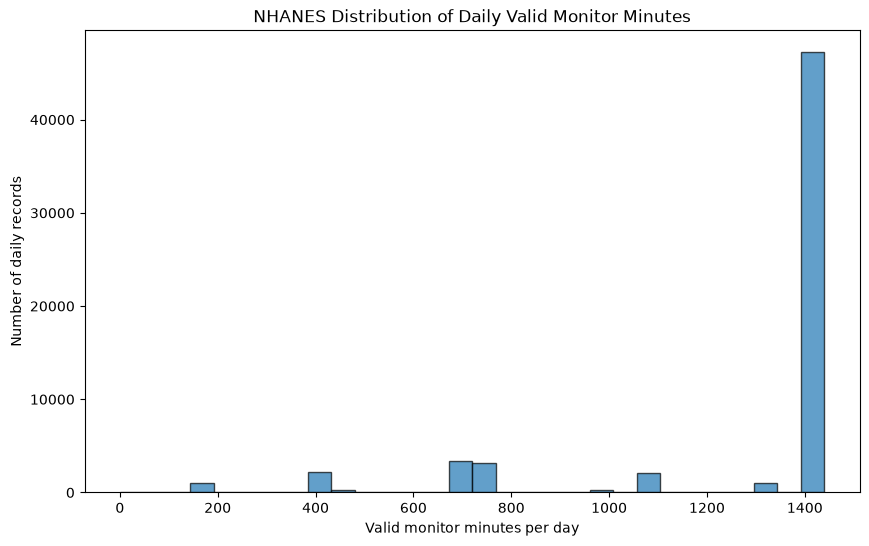

In [44]:
# Distribution of daily valid monitor minutes

plt.figure(figsize=(10, 6))

plt.hist(
    nhanes_clean["PAXVMD"].to_numpy(),
    bins=30,
    edgecolor="black",
    alpha=0.7
)

plt.xlabel("Valid monitor minutes per day")
plt.ylabel("Number of daily records")
plt.title("NHANES Distribution of Daily Valid Monitor Minutes")

plt.show()

### Interpretation
The distribution of daily valid monitoring minutes is strongly left-skewed. Most of the observations are concentrated near 1440 minutes, meaning that many daily records contain nearly a full day of valid monitoring data. However, there are smaller clusters that appear at approximately 180-190, 400, 700-750, and 1080-1100. This is important because that means there are some records that contain substantially fewer valid monitoring minutes. It could be that this distribution is due to something systematic rather than random.

It is important to investigate this distribution because differences in monitoring duration could affect comparisons of physical activity across participants. Individuals with fewer valid monitoring minutes may appear less active simply because less acitivity was recorded.

Are shorter monitoring durations concentrated on particular monitoring days, especially first and last day which were partial days?

## Relationship between Monitoring Day and Valid Monitor Minutes
We must investigate whether monitoring duration differs across monitoring days, particularly whether the first and last days contain fewer valid monitoring minutes.

PAXDAYD,MeanValidMinutes
i64,f64
1,501.140379
2,1436.144202
3,1434.900058
4,1433.818527
5,1433.417571
6,1434.380059
7,1432.773058
8,1431.381815
9,944.101695


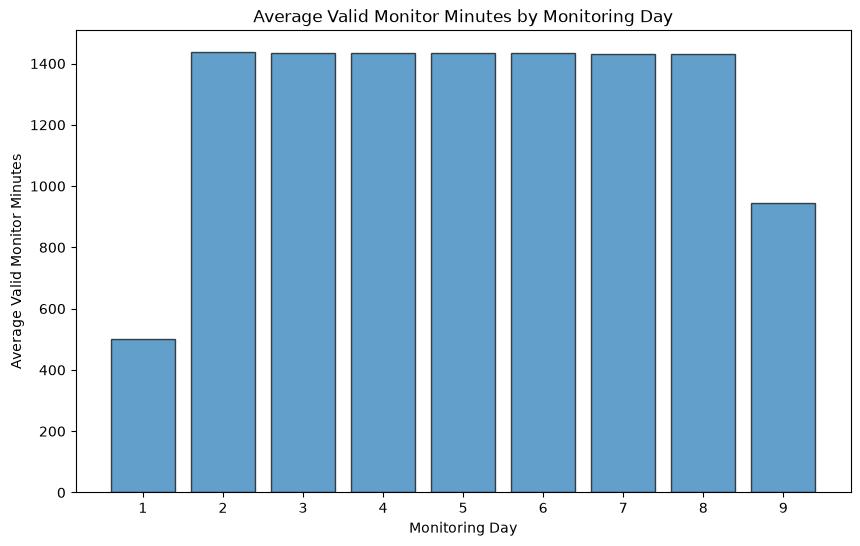

In [49]:
# Compare valid monitor minutes across monitoring days

nhanes_day_summary = (
    nhanes_clean
    .with_columns(
        pl.col("PAXDAYD").cast(pl.Int64)
    )
    .group_by("PAXDAYD")
    .agg(
        pl.col("PAXVMD").mean().alias("MeanValidMinutes")
    )
    .sort("PAXDAYD")
)

display(nhanes_day_summary)

plt.figure(figsize=(10, 6))

plt.bar(
    nhanes_day_summary["PAXDAYD"].to_numpy(),
    nhanes_day_summary["MeanValidMinutes"].to_numpy(),
    edgecolor="black",
    alpha=0.7
)

plt.xlabel("Monitoring Day")
plt.ylabel("Average Valid Monitor Minutes")
plt.title("Average Valid Monitor Minutes by Monitoring Day")

plt.xticks(nhanes_day_summary["PAXDAYD"].to_numpy())

plt.savefig(
    "figures/nhanes_monitoring_duration.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

### Interpretation
The first and last day were indeed partial days just as the CDC documentation stated, and every day in between was a complete day since they average 1400 minutes of monitoring minutes.

This finding is important because differences in monitoring duration could affect comparison of physical activity. Participants with shorter monitoring periods may appear as if they are less active simply because of fewer minutes recorded.

Does excluding the first and last monitoring days change the distribution of physical activity measurements. For our next analysis we should consider focusing on days 2-8 to improve comparability between daily observations.

## Relationship Between Weekday/Weekend and Monitor Wear Time
We will investigate whether average monitor wear time differs between weekdays and weekends. This comparison is important becaseu it will help us determine whether differences in monitoring coverage could affect our analysis of weekday and weekend phyiscal activity. For this investigation, we will focus on monitoring days 2-8 to reduce the influence that the partial first and last days have.

DayType,MeanWearMinutes
str,f64
"""Weekday""",844.533631
"""Weekend""",788.020836


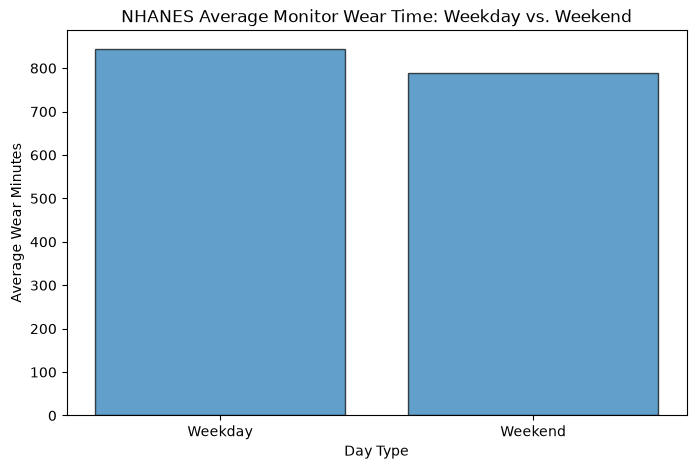

In [46]:
# Compare weekday and weekend monitor wear time

nhanes_weekday_data = (
    nhanes_clean
    .with_columns(
        pl.col("PAXDAYD").cast(pl.Int64),
        pl.col("PAXDAYWD").cast(pl.Int64)
    )
    .filter(
        pl.col("PAXDAYD").is_between(2, 8)
    )
    .with_columns(
        pl.when(pl.col("PAXDAYWD").is_in([1, 7]))
        .then(pl.lit("Weekend"))
        .otherwise(pl.lit("Weekday"))
        .alias("DayType")
    )
)

# Calculate average wear time by day type
nhanes_weekday_summary = (
    nhanes_weekday_data
    .group_by("DayType")
    .agg(
        pl.col("PAXWWMD").mean().alias("MeanWearMinutes")
    )
    .sort("DayType")
)

display(nhanes_weekday_summary)

# Create bar chart
plt.figure(figsize=(8, 5))

plt.bar(
    nhanes_weekday_summary["DayType"].to_list(),
    nhanes_weekday_summary["MeanWearMinutes"].to_numpy(),
    edgecolor="black",
    alpha=0.7
)

plt.xlabel("Day Type")
plt.ylabel("Average Wear Minutes")
plt.title("NHANES Average Monitor Wear Time: Weekday vs. Weekend")

plt.show()

### Interpretation
The difference between wear time on weekdays vs weekend is noticeable but it does not seem significant since the difference is around 1 hour more on weekdays vs weekends. This may suggest that monitoring coverage may differ depending on the day of the week.

This matters because participants who wear their monitors for longer periods have more opportunities to record physical activity. Therefore, the differences in recorded activity between weekdays and weekends may partially reflect differences in wear time rather than actual differences in physical activity. This result is somewhat unexpected because we did not initially know whether monitoring behavior would differ between weekdays and weekends.

Our next question should investigate whether physical activity intensity also differs between weekdays and weekends after accounting for monitoring duration.

We should also investigate activity measurements normalized by wear time to make comparisons between weekdays and weekends more meaningful.

## Relationship Between Day Type and Activity Measurements per Valid Minute
We will investigate whether the NHANES activity measurement PAXMTSD differs between weekdays and weekends because monitoring duration varies between these groups, we will also examine the measurement to valid monitor wear time. This will help us identify differences in daily activity patterns while accounting for differences in monitoring coverage.

DayType,MeanDailyMIMS,MeanMIMSPerValidMinute
str,f64,f64
"""Weekday""",13745.246221,9.582402
"""Weekend""",12664.393011,8.829825


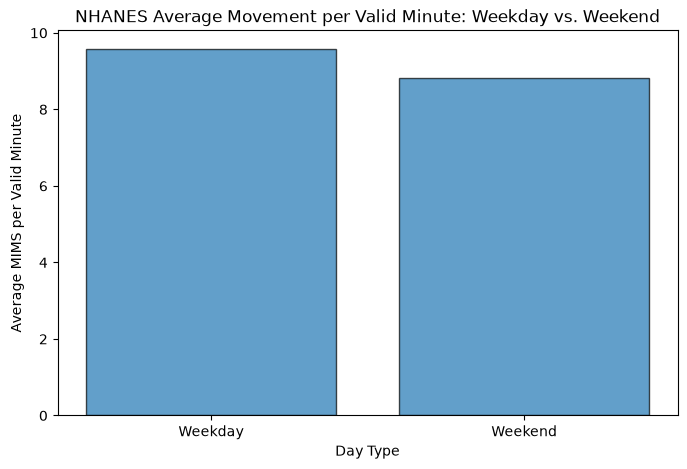

In [47]:
# Compare average movement per valid minute between weekdays and weekends

nhanes_activity_data = (
    nhanes_weekday_data
    .with_columns(
        pl.when(pl.col("PAXVMD") > 0)
        .then(pl.col("PAXMTSD") / pl.col("PAXVMD"))
        .otherwise(None)
        .alias("MovementPerValidMinute")
    )
)

# Calculate averages by day type
nhanes_activity_summary = (
    nhanes_activity_data
    .group_by("DayType")
    .agg(
        pl.col("PAXMTSD").mean().alias("MeanDailyMIMS"),
        pl.col("MovementPerValidMinute").mean().alias("MeanMIMSPerValidMinute")
    )
    .sort("DayType")
)

display(nhanes_activity_summary)

# Plot normalized movement measurements
plt.figure(figsize=(8, 5))

plt.bar(
    nhanes_activity_summary["DayType"].to_list(),
    nhanes_activity_summary["MeanMIMSPerValidMinute"].to_numpy(),
    edgecolor="black",
    alpha=0.7
)

plt.xlabel("Day Type")
plt.ylabel("Average MIMS per Valid Minute")
plt.title("NHANES Average Movement per Valid Minute: Weekday vs. Weekend")

plt.show()

## Interpretation
The bar chart shows that average movement per valid monitoring minute is higher on weekdays than on weekends.

This finding suggests that movement patterns may differ between weekdays and weekends because the measurements are normalized by valid monitoring duration, so the difference cannot be explained solely by the number of valid minutes recorded. The result is somewhat unexpected because we initially observed nearly identical weekday and weekend values when normalized by wake wear minutes. Using total valid monitoring minutes reveals a different pattern. However, these results are descriptive averages and do not establish that the difference is statistically significant.

Next, we could investigate whether weekday-weekend movement differences remain consistent across individual participants. We could also examine whether the movement patterns vary by monitoring day or particiaptn characteristics.

Possible research question:
Do participants exhibit higher average movement per valid monitoring minute on weekdays than on weekends, and does this pattern remain consistent across inidivuduals?